# 2.9.2 문항 8 조건 변경 참고 실습

기존 linear_regression_toy.csv의 120행과 x·y 두 열을 사용합니다. 가중치와 절편의 영향을 분리하기 쉬워 선택한 교육용 자료입니다.

선정 이유: 기준 프로그램의 조건 하나를 바꾼 참고 구현입니다. 코드 차이와 실제 결과를 대조하고 테스트 결과로 가장 좋은 조건을 반복 선택하지 않습니다. 원인 해석과 보고서는 독자가 작성합니다.

커널을 다시 시작한 뒤 각 셀을 위에서 아래로 실행합니다. 코드에는 가져오기와 함수 정의도 포함되어 있습니다.

## 셀 1 라이브러리 가져오기

가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 파이토치(PyTorch)의 텐서·자동 미분 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

In [1]:
# 가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from pathlib import Path

# 가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import json

# 가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import numpy as np

# 가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import pandas as pd

# 가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import matplotlib.pyplot as plt

# 가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from IPython.display import display, Image as NotebookImage

# 가져오기(Import) 문장으로 파이토치(PyTorch)의 텐서·자동 미분 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import torch

## 셀 2 입력·계산·출력 확인

계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.

현재 노트북 또는 프로그램 폴더(Current Directory, HERE)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

장 폴더(Chapter Directory, CHAPTER)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

입력 자료 폴더(Data Directory, DATA)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

결과 저장 폴더(Output Directory, OUT)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

앞 셀의 값을 사용하여 OUT.mkdir(parents=True, exist_ok=True) 동작을 수행합니다. 셀 순서를 바꾸거나 중간 셀을 생략하지 않습니다.

검증 조건(Assertion)이 참인지 확인합니다. 거짓이면 셀을 중단하며 성공한 결과로 기록하지 않습니다.

In [2]:
# 계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":11,
    "axes.prop_cycle":plt.cycler(color=["black","0.45","0.7"]),
    "svg.fonttype":"none", "figure.figsize":(7.0,4.2)})

# 현재 노트북 또는 프로그램 폴더(Current Directory, HERE)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
HERE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()

# 장 폴더(Chapter Directory, CHAPTER)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
CHAPTER = HERE if (HERE / "data").exists() else HERE.parent

# 입력 자료 폴더(Data Directory, DATA)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
DATA = CHAPTER / "data"

# 결과 저장 폴더(Output Directory, OUT)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
OUT = HERE / "results" / "q08_parameter_change"

# 앞 셀의 값을 사용하여 OUT.mkdir(parents=True, exist_ok=True) 동작을 수행합니다. 셀 순서를 바꾸거나 중간 셀을 생략하지 않습니다.
OUT.mkdir(parents=True, exist_ok=True)

# 검증 조건(Assertion)이 참인지 확인합니다. 거짓이면 셀을 중단하며 성공한 결과로 기록하지 않습니다.
assert DATA.exists(), f"장별 data 폴더가 없습니다: {DATA}. 저장소 전체를 내려받으세요."

## 셀 3 함수와 모듈 정의

현재 계산으로 만든 그림을 SVG와 300dpi PNG로 저장하고 노트북 셀에 표시합니다.

In [3]:
# 현재 계산으로 만든 그림을 SVG와 300dpi PNG로 저장하고 노트북 셀에 표시합니다.
def figure(out, name):
    # 실제 현재 그림을 벡터와 300dpi 흑백 삽입본으로 저장합니다.
    plt.tight_layout()
    plt.savefig(out / (name + ".svg"), facecolor="white")
    plt.savefig(out / (name + ".png"), dpi=300, facecolor="white")
    if "get_ipython" in globals():
        display(NotebookImage(filename=str(out / (name + ".png"))))
    plt.close()

## 셀 4 함수와 모듈 정의

계산한 지표를 JSON 파일과 셀의 문자 출력으로 기록합니다.

In [4]:
# 계산한 지표를 JSON 파일과 셀의 문자 출력으로 기록합니다.
def report(out, name, metrics):
    # 계산된 값만 기록하며 비유한 수치를 성공값으로 바꾸지 않습니다.
    text = json.dumps(metrics, ensure_ascii=False, indent=2, allow_nan=False)
    (out / (name + ".json")).write_text(text, encoding="utf-8")
    print(text)

## 셀 5 입력·계산·출력 확인

난수 초기값(Random Seed, SEED)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

앞 셀의 값을 사용하여 torch.manual_seed(SEED) 동작을 수행합니다. 셀 순서를 바꾸거나 중간 셀을 생략하지 않습니다.

변수 data에 CSV 파일을 표로 읽습니다. 열 이름과 목표 열을 다음 출력에서 확인합니다.

입력 특성 행렬(Feature Matrix, X)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

목표 벡터(Target Vector, y)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

가중치(Weight, W)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

절편(Bias, b)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

변수 learning_rate를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

반복 기록(Iteration History, history)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

In [5]:
# 난수 초기값(Random Seed, SEED)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
SEED = 42

# 앞 셀의 값을 사용하여 torch.manual_seed(SEED) 동작을 수행합니다. 셀 순서를 바꾸거나 중간 셀을 생략하지 않습니다.
torch.manual_seed(SEED)

# 변수 data에 CSV 파일을 표로 읽습니다. 열 이름과 목표 열을 다음 출력에서 확인합니다.
data = pd.read_csv(DATA / "main_math_sample.csv")

# 입력 특성 행렬(Feature Matrix, X)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
X = torch.tensor(data["x"].values, dtype=torch.float32).unsqueeze(1)

# 목표 벡터(Target Vector, y)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
y = torch.tensor(data["y"].values, dtype=torch.float32).unsqueeze(1)

# 가중치(Weight, W)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
W = torch.zeros(1, requires_grad=True)

# 절편(Bias, b)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
b = torch.zeros(1, requires_grad=True)

# 변수 learning_rate를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
learning_rate = 0.02

# 반복 기록(Iteration History, history)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
history = []

## 셀 6 입력·계산·출력 확인

반복 조건 for epoch in range(301):에 따라 같은 처리를 수행합니다. 루프 내부의 들여쓰기는 반복마다 실행되며 반복 종료 뒤 변수에는 마지막 계산 상태가 남습니다.

계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.

계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.

계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.

계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.

계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.

In [6]:
# 반복 조건 for epoch in range(301):에 따라 같은 처리를 수행합니다. 루프 내부의 들여쓰기는 반복마다 실행되며 반복 종료 뒤 변수에는 마지막 계산 상태가 남습니다.
for epoch in range(301):
    hypothesis = X * W + b
    cost = torch.mean((hypothesis - y) ** 2)
    history.append(cost.item())
    cost.backward()
    with torch.no_grad():
        W -= learning_rate * W.grad
        b -= learning_rate * b.grad
        W.grad.zero_()
        b.grad.zero_()
    if epoch % 60 == 0:
        print(f"Epoch {epoch:3d}/300 | Cost: {cost.item():.6f} | W: {W.item():.4f} | b: {b.item():.4f}")

# 계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.
plt.plot(history, color="black")

# 계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.
plt.xlabel("Epoch")

# 계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.
plt.ylabel("Mean Squared Error")

# 계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.
plt.title("Gradient Descent Loss")

# 계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.
plt.grid(alpha=0.3)

Epoch   0/300 | Cost: 81.064667 | W: 0.9030 | b: 0.1645
Epoch  60/300 | Cost: 4.132294 | W: 2.6641 | b: 3.7724
Epoch 120/300 | Cost: 4.007066 | W: 2.6641 | b: 4.0840
Epoch 180/300 | Cost: 4.006133 | W: 2.6641 | b: 4.1109
Epoch 240/300 | Cost: 4.006125 | W: 2.6641 | b: 4.1132
Epoch 300/300 | Cost: 4.006125 | W: 2.6641 | b: 4.1134


## 셀 7 입력·계산·출력 확인

계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.

실제 계산한 그림을 저장하고 출력합니다. 가로축·세로축·범례의 의미는 이 실습의 결과 해설에서 확인합니다.

계산된 값만 결과 파일과 셀 출력에 기록합니다. 이후 비교에는 출력 파일과 데이터 버전을 함께 사용합니다.

{
  "W": 2.664077043533325,
  "b": 4.1133832931518555,
  "last_preupdate_loss": 4.006124973297119,
  "steps": 301
}


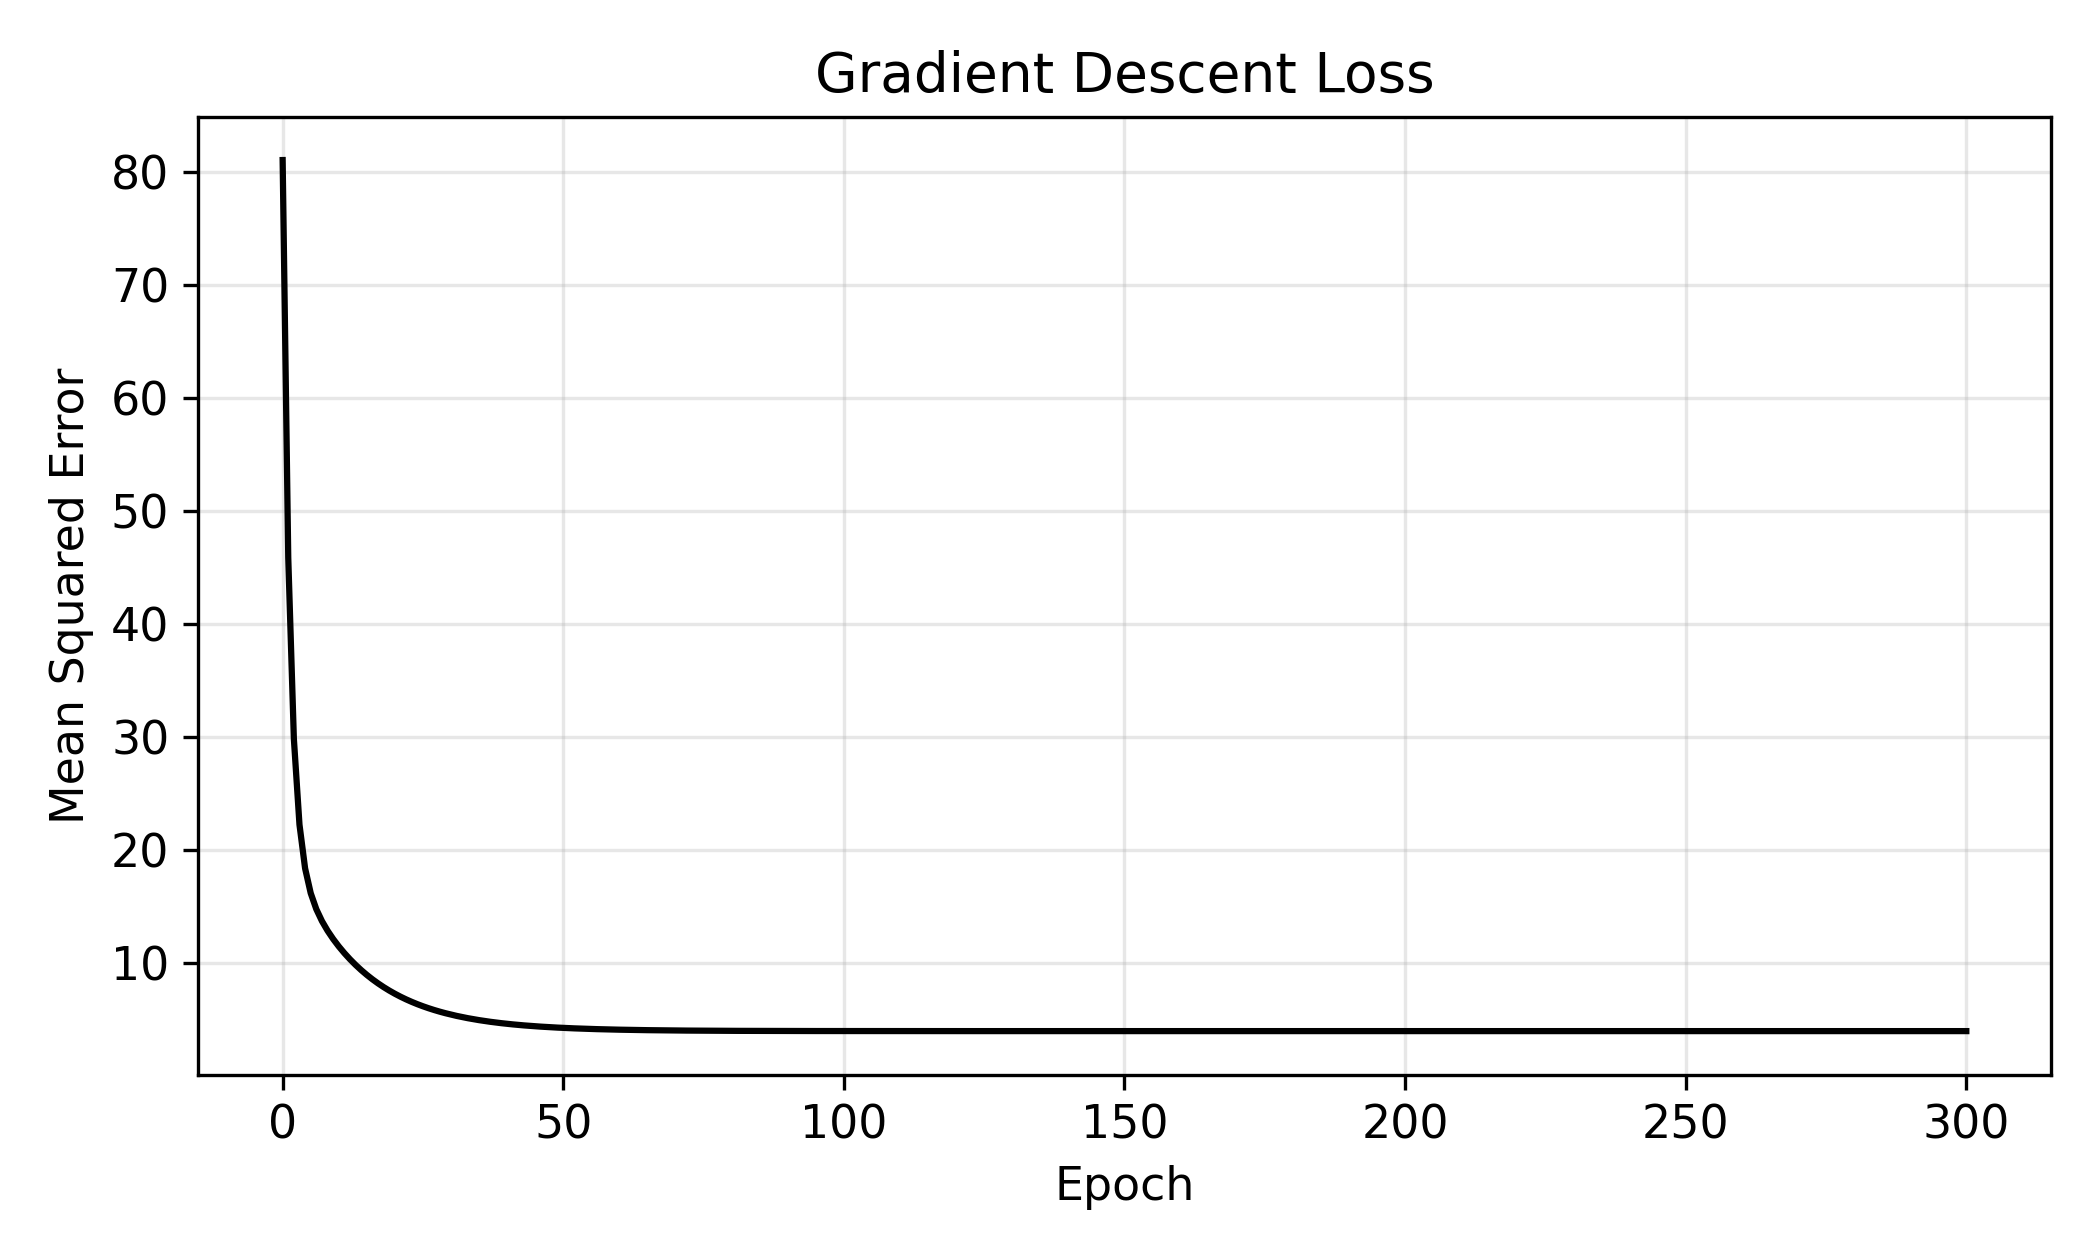

In [7]:
# 계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.
plt.tight_layout()

# 실제 계산한 그림을 저장하고 출력합니다. 가로축·세로축·범례의 의미는 이 실습의 결과 해설에서 확인합니다.
figure(OUT, "ch02_gradient_descent_loss")

# 계산된 값만 결과 파일과 셀 출력에 기록합니다. 이후 비교에는 출력 파일과 데이터 버전을 함께 사용합니다.
report(OUT,"summary",{"W":float(W.detach()),"b":float(b.detach()),"last_preupdate_loss":history[-1],"steps":len(history)})

## 그림과 결과 해석

기준 프로그램의 조건 하나를 바꾼 참고 구현입니다. 코드 차이와 실제 결과를 대조하고 테스트 결과로 가장 좋은 조건을 반복 선택하지 않습니다. 원인 해석과 보고서는 독자가 작성합니다. 손실은 같은 입력의 훈련 오차입니다. 가중치와 절편의 갱신 및 학습률에 따른 안정성을 함께 봅니다.